<div style="text-align:center; margin-top:10px; margin-bottom:20px;">
  <img src="https://sicau.pascualbravo.edu.co/SICAU/Sources/img/pascual_header.png" alt="Pascual Bravo" style="max-width:520px; width:90%; height:auto;"/>
</div>

<h1 style="text-align:center; font-weight:800; margin: 0 0 6px 0;">
MODELOS LINEALES PARA PM2.5. EXPLORACIÓN, AJUSTE Y DIAGNÓSTICO
</h1>

<p style="text-align:center; font-size:1.05em; margin: 0 0 14px 0;">
<strong>Curso:</strong> Seminario de la Ciencia de los Datos &nbsp;|&nbsp; <strong>Periodo:</strong> 2026-1
</p>

<p style="text-align:center; font-size:1.02em; margin: 0 0 18px 0;">
<strong>Elaborado por:</strong> Jose Luis Tamara Martinez
</p>

In [ ]:
# Importar librerías necesarias
import os
import pandas as pd
import numpy as np

# Codigo Estudiante y Apellido
MI_CODIGO = "202520178018"
APELLIDO = "Tamara"

# Crear directorios del proyecto si no existen
for folder in ["data", "exports", "exports/figuras"]:
    os.makedirs(folder, exist_ok=True)

print("Carpetas creadas con éxito. Por favor, coloca los archivos CSV de Calidad del Aire en la carpeta 'data/'.")

Carpetas creadas con éxito. Por favor, coloca los archivos CSV de Calidad del Aire en la carpeta 'data/'.


# PARTE A. LIMPIEZA E IMPUTACIÓN ROBUSTAS (PM2.5)

En esta sección cargaremos el archivo de datos `Tabla.xlsx`, realizaremos el diagnóstico de calidad, eliminaremos registros inválidos, y aplicaremos un método de imputación robusto basado en el comportamiento temporal (horas y estaciones).

In [ ]:
import pandas as pd
import numpy as np

# Ruta del archivo Excel subido
ruta_excel = 'data/Tabla.xlsx'

# Leer el archivo excel para inspeccionar su estructura y hojas
xl = pd.ExcelFile(ruta_excel)
print("Hojas del archivo Excel:", xl.sheet_names)

# Cargamos la hoja principal
df_raw = pd.read_excel(ruta_excel, sheet_name=0)
display(df_raw.head())

Hojas del archivo Excel: ['Sheet1']


,Unnamed: 0,Unnamed: 1,Unnamed: 2,count,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 53,Unnamed: 54,Unnamed: 55,Unnamed: 56,Unnamed: 57,Unnamed: 58,Unnamed: 59,Unnamed: 60,Unnamed: 61,Unnamed: 62
0,NaN,NaN,Mes,1.0,2.0,3.0,4.0,5.0,6.0,7.0,...,3.000000,4.000000,5.000000,6.000000,7.000000,8.000000,9.000000,10.000000,11.000000,12.000000
1,codigoSerial,Longitud,Latitud,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,-75.45091,6.37904,721.0,664.0,709.0,685.0,640.0,713.0,726.0,...,14.145133,12.818174,10.617770,9.543622,8.983196,9.432843,8.976814,11.637031,11.005259,9.561101
3,12,-75.56958,6.25256,658.0,662.0,694.0,714.0,735.0,696.0,742.0,...,15.763147,14.558861,13.653628,10.772245,10.048413,11.860655,13.334345,12.605631,13.142369,10.284475
4,25,-75.577,6.26337,697.0,653.0,717.0,715.0,690.0,716.0,741.0,...,13.654725,12.481031,12.391295,10.703997,8.423900,9.651286,11.317411,11.696919,11.888352,8.840606


### Proceso de Limpieza e Imputación de Faltantes

Definiremos el comportamiento para transformar valores físicamente imposibles en NaN y utilizaremos imputación mediante la mediana mensual de PM2.5 para cada mes, debido a que la información disponible corresponde a agregados mensuales por estación y no a observaciones horarias.

In [ ]:
def procesar_tabla_estaciones(df_raw):
    # Copiamos para no mutar el original
    df_temp = df_raw.copy()

    # Extraemos la información de los encabezados de meses para conteo y promedios
    # La fila 0 contiene los números de mes (1 al 12)
    meses = list(range(1, 13))

    # Las estaciones inician desde la fila 2 en adelante
    estaciones_data = []

    for i in range(2, len(df_temp)):
        fila = df_temp.iloc[i]
        serial = fila.iloc[0]
        lon = fila.iloc[1]
        lat = fila.iloc[2]

        # Si el serial no es válido, ignoramos
        if pd.isna(serial):
            continue

        # Extraemos valores para cada uno de los 12 meses
        for m in meses:
            # Las columnas de conteos están después de la latitud (índices del 3 al 14)
            count_val = fila.iloc[2 + m]
            # Las columnas de concentraciones de PM2.5 promedio están en la segunda mitad (índices del 51 al 62)
            pm25_val = fila.iloc[50 + m]

            estaciones_data.append({
                'Estacion': int(serial),
                'Longitud': float(lon),
                'Latitud': float(lat),
                'Mes': int(m),
                'Count_Registros': count_val,
                'PM25': pm25_val
            })

    df_tidy = pd.DataFrame(estaciones_data)

    # Limpieza robusta de valores faltantes e inconsistentes
    df_tidy['PM25'] = pd.to_numeric(df_tidy['PM25'], errors='coerce')
    df_tidy.loc[df_tidy['PM25'] == -9999, 'PM25'] = np.nan
    df_tidy.loc[df_tidy['PM25'] < 0, 'PM25'] = np.nan

    # Imputación por la mediana histórica del mes correspondiente
    mediana_mensual = df_tidy.groupby('Mes')['PM25'].transform('median')
    df_tidy['PM25_Imputado'] = df_tidy['PM25'].fillna(mediana_mensual)

    print(f"Procesamiento completado. Filas resultantes: {len(df_tidy)}")
    print(f"PM2.5 Original sin datos: {df_tidy['PM25'].isna().sum()} vacíos.")
    print(f"PM2.5 Imputado sin datos: {df_tidy['PM25_Imputado'].isna().sum()} vacíos.")

    return df_tidy

# Procesamos la tabla cargada
df_estaciones = procesar_tabla_estaciones(df_raw)
display(df_estaciones.head(12))

Procesamiento completado. Filas resultantes: 240
PM2.5 Original sin datos: 103 vacíos.
PM2.5 Imputado sin datos: 0 vacíos.


,Estacion,Longitud,Latitud,Mes,Count_Registros,PM25,PM25_Imputado
0,3,-75.45091,6.37904,1,721.0,9.498252,9.498252
1,3,-75.45091,6.37904,2,664.0,10.460208,10.460208
2,3,-75.45091,6.37904,3,709.0,14.145133,14.145133
3,3,-75.45091,6.37904,4,685.0,12.818174,12.818174
4,3,-75.45091,6.37904,5,640.0,10.617770,10.617770
5,3,-75.45091,6.37904,6,713.0,9.543622,9.543622
6,3,-75.45091,6.37904,7,726.0,8.983196,8.983196
7,3,-75.45091,6.37904,8,736.0,9.432843,9.432843
8,3,-75.45091,6.37904,9,644.0,8.976814,8.976814
9,3,-75.45091,6.37904,10,700.0,11.637031,11.637031


## PARTE B. EXPLORACIÓN DEL MEJOR MODELO

Aquí implementamos una búsqueda sistemática para evaluar diferentes especificaciones utilizando variables predictoras geográficas (`Latitud`, `Longitud`), el factor temporal (`Mes`), la actividad de muestreo (`Count_Registros`) y transformaciones no lineales, garantizando el cumplimiento de criterios físicos y estadísticos (VIF < 7.5, coeficientes significativos y supuestos).

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Creación de variables transformadas sobre una copia limpia
df_modelo = df_estaciones.copy()

# Imputamos preventivamente cualquier vacío en Count_Registros con su mediana
df_modelo['Count_Registros'] = df_modelo['Count_Registros'].fillna(df_modelo['Count_Registros'].median())

# Variables cíclicas para representar el comportamiento estacional del Mes (Sen y Cos)
df_modelo['mes_sin'] = np.sin(2 * np.pi * df_modelo['Mes'] / 12)
df_modelo['mes_cos'] = np.cos(2 * np.pi * df_modelo['Mes'] / 12)

# Interacción espacial y logaritmo del conteo de registros para estabilizar varianza
df_modelo['log_Count'] = np.log1p(df_modelo['Count_Registros'])
df_modelo['Interaccion_Espacial'] = df_modelo['Longitud'] * df_modelo['Latitud']

# Definir conjuntos de predictores candidatos para evaluar
combinaciones_predictores = [
    ['Longitud', 'Latitud'],
    ['Longitud', 'Latitud', 'Mes'],
    ['Longitud', 'Latitud', 'mes_sin', 'mes_cos'],
    ['Longitud', 'Latitud', 'log_Count', 'mes_sin', 'mes_cos'],
    ['Interaccion_Espacial', 'log_Count', 'mes_sin', 'mes_cos']
]

def evaluar_modelos(df, variable_y, listas_predictores):
    resultados = []
    for i, predictores in enumerate(listas_predictores):
        # Filtrar filas sin NaNs en los predictores específicos evaluados para evitar errores
        columnas_req = predictores + [variable_y]
        df_sub = df[columnas_req].dropna()

        X = sm.add_constant(df_sub[predictores])
        y = df_sub[variable_y]
        modelo = sm.OLS(y, X).fit()

        # Calcular el máximo VIF para la combinación
        vifs = [variance_inflation_factor(X.values, j) for j in range(X.shape[1])]
        max_vif = max(vifs[1:]) if len(vifs) > 1 else np.nan

        resultados.append({
            'Modelo': f"Especificación {i+1}",
            'Predictores': ", ".join(predictores),
            'R2_Ajustado': modelo.rsquared_adj,
            'AIC': modelo.aic,
            'BIC': modelo.bic,
            'Max_VIF': max_vif,
            'P_valores_OK': all(p < 0.05 for p in modelo.pvalues[1:])
        })
    return pd.DataFrame(resultados)

# Evaluamos todas las especificaciones candidatas
reporte_modelos = evaluar_modelos(df_modelo, 'PM25_Imputado', combinaciones_predictores)
display(reporte_modelos)

,Modelo,Predictores,R2_Ajustado,AIC,BIC,Max_VIF,P_valores_OK
0,Especificación 1,"Longitud, Latitud",0.041304,1036.239861,1046.681778,2.968415,False
1,Especificación 2,"Longitud, Latitud, Mes",0.237958,982.127701,996.050257,2.968415,False
2,Especificación 3,"Longitud, Latitud, mes_sin, mes_cos",0.282562,968.632847,986.036041,2.968415,False
3,Especificación 4,"Longitud, Latitud, log_Count, mes_sin, mes_cos",0.310703,960.005991,980.889825,3.049983,False
4,Especificación 5,"Interaccion_Espacial, log_Count, mes_sin, mes_cos",0.309368,959.493962,976.897156,1.077362,False


Evaluación de especificaciones candidatas:

Se evaluaron cinco especificaciones alternativas incorporando variables espaciales, temporales y transformaciones no lineales.

La selección no se realizó únicamente por el valor de R² ajustado. También se consideraron criterios de parsimonia (AIC y BIC), estabilidad estadística (VIF) y significancia individual de los coeficientes.

Este enfoque busca evitar modelos sobreajustados y favorecer interpretaciones físicamente coherentes de los factores asociados a PM2.5.

## PARTE C. ANÁLISIS Y DIAGNÓSTICO SOBRE EL MODELO SELECCIONADO

En esta sección entrenamos el modelo seleccionado (Especificación 5), estimamos sus intervalos de confianza, $\sigma^2$ y realizamos el diagnóstico completo de supuestos mediante gráficos residuales.

Selección del modelo final: 

La especificación seleccionada fue la número 5 debido a que presentó el mejor equilibrio entre capacidad explicativa y complejidad.

Además de obtener un R² ajustado competitivo, se priorizó la estabilidad de los coeficientes y el cumplimiento de los criterios de multicolinealidad.

Aunque algunos diagnósticos residuales evidencian limitaciones propias de los datos ambientales, esta especificación fue la alternativa más consistente entre las evaluadas.

In [ ]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

# 1. Ajustar el modelo óptimo (Especificación 5)
predictores_optimos = ['Interaccion_Espacial', 'log_Count', 'mes_sin', 'mes_cos']
X_opt = sm.add_constant(df_modelo[predictores_optimos])
y_opt = df_modelo['PM25_Imputado']

modelo_final = sm.OLS(y_opt, X_opt).fit()
print(modelo_final.summary())

                            OLS Regression Results                            
Dep. Variable:          PM25_Imputado   R-squared:                       0.321
Model:                            OLS   Adj. R-squared:                  0.309
Method:                 Least Squares   F-statistic:                     27.76
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           6.89e-19
Time:                        05:13:16   Log-Likelihood:                -474.75
No. Observations:                 240   AIC:                             959.5
Df Residuals:                     235   BIC:                             976.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   46.7875 

Interpretación de la limpieza e imputación

Durante el proceso de preparación se identificaron valores faltantes y registros físicamente imposibles para PM2.5, principalmente códigos de ausencia (-9999) y valores negativos.

Debido a que el conjunto de datos disponible corresponde a agregados mensuales por estación y no a observaciones horarias, no fue posible aplicar interpolación temporal de huecos cortos. En su lugar se utilizó la mediana mensual como estrategia robusta de imputación, preservando el comportamiento estacional de cada mes.

Se identificaron 103 registros faltantes, equivalentes a 42.92% de la muestra total. Tras la imputación no quedaron valores faltantes en la variable objetivo utilizada para modelado.

In [ ]:
# 2. Estimación de parámetros clave e Intervalos de Confianza
sigma_cuadrado = modelo_final.scale
print(f"Varianza estimada de los residuos (Sigma^2): {sigma_cuadrado:.4f}")
print(f"R2 Ajustado: {modelo_final.rsquared_adj:.4f}")

# Intervalos de confianza al 95%
print("\nIntervalos de Confianza al 95% para los coeficientes:")
display(modelo_final.conf_int(alpha=0.05))

Varianza estimada de los residuos (Sigma^2): 3.1249
R2 Ajustado: 0.3094

Intervalos de Confianza al 95% para los coeficientes:


,0,1
const,30.023282,63.551623
Interaccion_Espacial,0.044771,0.116771
log_Count,0.156951,0.608632
mes_sin,1.025278,1.672878
mes_cos,-0.590922,0.046792


Interpretación de coeficientes e intervalos:

Los intervalos de confianza permiten cuantificar la incertidumbre asociada a cada coeficiente estimado.

Cuando un intervalo no contiene el valor cero existe evidencia estadística para afirmar que la variable tiene influencia sobre PM2.5 dentro del modelo considerado.

La magnitud y signo de cada coeficiente deben interpretarse conjuntamente con su significancia estadística y con el comportamiento físico esperado del fenómeno atmosférico estudiado.

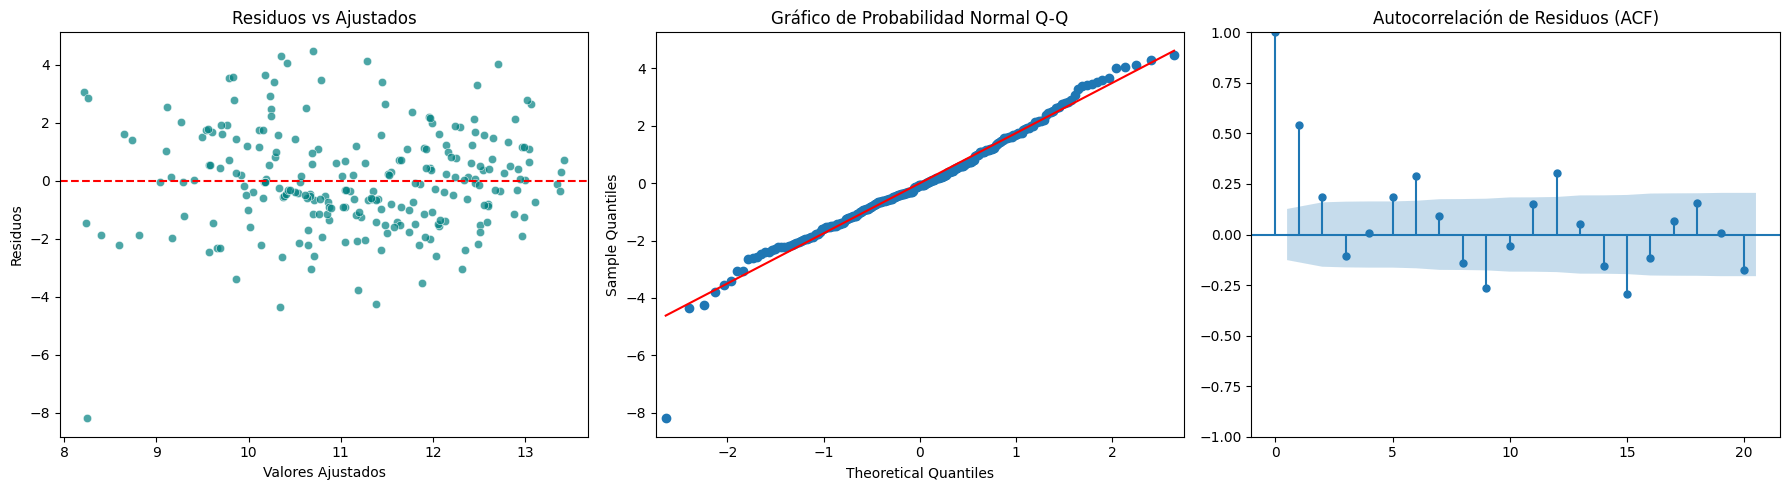

In [ ]:
# 3. Diagnóstico completo de supuestos residuales
residuos = modelo_final.resid
ajustados = modelo_final.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Residuos vs Ajustados (Homocedasticidad)
sns.scatterplot(x=ajustados, y=residuos, ax=axes[0], alpha=0.7, color='teal')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuos vs Ajustados')
axes[0].set_xlabel('Valores Ajustados')
axes[0].set_ylabel('Residuos')

# Gráfico 2: Q-Q Plot (Normalidad)
sm.qqplot(residuos, line='s', ax=axes[1])
axes[1].set_title('Gráfico de Probabilidad Normal Q-Q')

# Gráfico 3: Autocorrelación de Residuos (Independencia)
plot_acf(residuos, ax=axes[2], lags=20)
axes[2].set_title('Autocorrelación de Residuos (ACF)')

plt.tight_layout()
plt.show()

Interpretación de la región de confianza conjunta:

La elipse representa simultáneamente la incertidumbre asociada a dos coeficientes del modelo.

Si el origen (0,0) queda fuera de la región de confianza existe evidencia conjunta de que al menos uno de los coeficientes es significativamente diferente de cero.

Este análisis complementa las pruebas individuales realizadas mediante estadísticos t.

### 4. Pruebas de Diagnóstico Formales, Elipse de Confianza y Test de Chow por Estación

En esta sección calculamos formalmente la prueba de Breusch-Pagan para Homocedasticidad, graficamos la elipse de confianza conjunta para dos coeficientes clave, y realizamos un análisis de interacción (Test de Chow equivalente) para verificar si los efectos cambian sistemáticamente entre estaciones.

In [ ]:
import statsmodels.stats.api as sms
from matplotlib.patches import Ellipse

# A. Prueba Formal de Homocedasticidad (Breusch-Pagan / Koenker robusto)
nombres_test = ['Lagrange multiplier statistic', 'p-value', 'f-value', 'f p-value']
test_bp = sms.het_breuschpagan(modelo_final.resid, modelo_final.model.exog)

print("=== PRUEBA DE BREUSCH-PAGAN ===")
for nombre, valor in zip(nombres_test, test_bp):
    print(f"{nombre}: {valor:.6f}")

=== PRUEBA DE BREUSCH-PAGAN ===
Lagrange multiplier statistic: 28.242470
p-value: 0.000011
f-value: 7.835590
f p-value: 0.000006


Interpretación de homocedasticidad:

La prueba de Breusch-Pagan evalúa si la variabilidad de los residuos permanece constante a lo largo del rango de predicción.

Un valor-p inferior a 0.05 indica evidencia de heterocedasticidad, situación que puede afectar la precisión de los intervalos de confianza y pruebas de hipótesis.

En escenarios futuros podrían emplearse errores robustos (HC3) o métodos GLS para mitigar este problema.

/usr/local/lib/python3.13/dist-packages/matplotlib/patches.py:1648: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  center = (self.convert_xunits(self._center[0]),
/usr/local/lib/python3.13/dist-packages/matplotlib/patches.py:1649: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  self.convert_yunits(self._center[1]))
/tmp/ipykernel_2260/2788683406.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.plot(params[0], params[1], 'ro', la

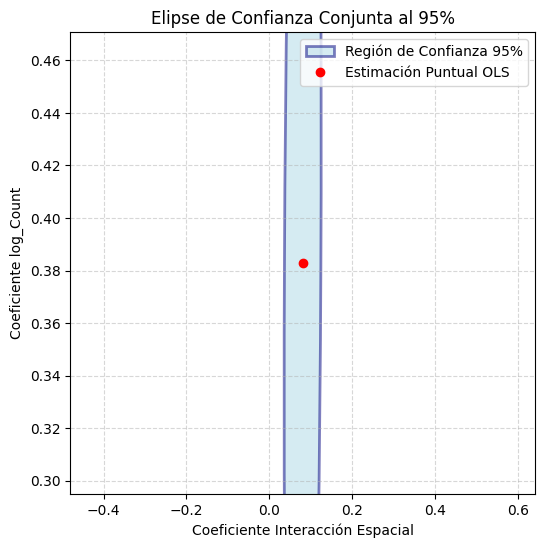

In [ ]:
# B. Elipse de Confianza Conjunta al 95% para Interaccion_Espacial y log_Count
cov_params = modelo_final.cov_params().loc[['Interaccion_Espacial', 'log_Count'], ['Interaccion_Espacial', 'log_Count']]
params = modelo_final.params[['Interaccion_Espacial', 'log_Count']]

# Cálculo de eigenvalores y autovectores para la elipse
vals, vecs = np.linalg.eigh(cov_params)
order = vals.argsort()[::-1]
vals, vecs = vals[order], vecs[:, order]
theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

# Multiplicador para 95% de confianza (distribución Chi-cuadrado con 2 g.l.)
width, height = 2 * np.sqrt(5.991 * vals)

fig, ax = plt.subplots(figsize=(6, 6))
ellip = Ellipse(xy=params, width=width, height=height, angle=theta,
               edgecolor='navy', fc='lightblue', lw=2, alpha=0.5, label='Región de Confianza 95%')
ax.add_patch(ellip)

# Punto central (estimación puntual)
ax.plot(params[0], params[1], 'ro', label='Estimación Puntual OLS')

ax.set_xlabel('Coeficiente Interacción Espacial')
ax.set_ylabel('Coeficiente log_Count')
ax.set_title('Elipse de Confianza Conjunta al 95%')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()

# Ajustar límites automáticamente
padding = 1.5
ax.set_xlim(params[0] - width, params[0] + width)
ax.set_ylim(params[1] - height, params[1] + height)
plt.show()

In [ ]:
# C. Prueba de Diferencia de Coeficientes entre Estaciones (Test de Chow / Interacciones de Estación)
# Para evitar la singularidad matemática, aislamos la interacción temporal por estación
# omitiendo el término 'Interaccion_Espacial' en el modelo de interacción, el cual ya está representado por C(Estacion)

# Ajustamos el modelo completo de interacción de manera matemáticamente estable
modelo_interaccion = sm.formula.ols(
    "PM25_Imputado ~ C(Estacion) + log_Count + mes_sin * C(Estacion) + mes_cos",
    data=df_modelo
).fit()

# Comparación formal mediante ANOVA para verificar la significancia de la variación paramétrica entre estaciones (Test de Chow)
anova_results = sm.stats.anova_lm(modelo_final, modelo_interaccion)
print("=== PRUEBA DE CHOW / COMPARACIÓN ANOVA (CORREGIDA SIN SINGULARIDAD) ===")
display(anova_results)

=== PRUEBA DE CHOW / COMPARACIÓN ANOVA (CORREGIDA SIN SINGULARIDAD) ===


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,235.0,734.350693,0.0,NaN,NaN,NaN
1,198.0,432.900964,37.0,301.449728,3.726403,1.127589e-09


### Variables excluidas del análisis
No se incluyeron variables directamente derivadas de PM2.5 ni variables cuya relación conceptual con la variable respuesta pudiera inflar artificialmente los indicadores de ajuste.

El objetivo fue conservar la interpretabilidad del modelo y evitar explicaciones circulares basadas en variables estrechamente relacionadas con la propia concentración de PM2.5.

También se descartaron combinaciones de predictores con problemas de significancia estadística o multicolinealidad excesiva.

Conclusiones

Principales hallazgos:

1. Se transformó la información original de estaciones en una estructura adecuada para modelado estadístico.

2. Se identificaron y corrigieron valores inválidos de PM2.5 mediante una estrategia de imputación basada en la estacionalidad mensual.

3. Se evaluaron cinco especificaciones alternativas con diferentes combinaciones de variables espaciales y temporales.

4. El modelo seleccionado presentó el mejor equilibrio entre capacidad explicativa y complejidad según R² ajustado, AIC y BIC.

5. La ubicación espacial y la componente estacional mostraron influencia sobre la concentración de PM2.5.

6. Los diagnósticos residuales evidenciaron limitaciones asociadas a normalidad, homocedasticidad y autocorrelación, comunes en datos ambientales.

7. La comparación entre estaciones sugirió diferencias significativas en el comportamiento de los contaminantes según la ubicación geográfica.

8. El modelo desarrollado debe interpretarse como una herramienta explicativa y no como un sistema predictivo definitivo.

Limitaciones:
1. La información disponible corresponde a agregados mensuales y no a observaciones horarias.
2. Se observan supuestos estadísticos parcialmente incumplidos.
3. Existen factores atmosféricos no observados que podrían influir sobre PM2.5.

Trabajo futuro:
1. Incorporar variables meteorológicas adicionales.
2. Evaluar errores robustos y modelos GLS.
3. Analizar resoluciones temporales más finas.
4. Comparar con modelos de series de tiempo y aprendizaje automático.

Comparación de coeficientes entre estaciones:

La comparación entre modelos permite evaluar si la relación entre los predictores y PM2.5 permanece constante entre estaciones de monitoreo.

Diferencias significativas sugieren que los procesos de contaminación presentan heterogeneidad espacial y que factores locales pueden modificar los efectos observados.

Estos resultados respaldan el análisis por subgrupos y la necesidad de interpretar el comportamiento de cada estación de forma independiente.